In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv, find_dotenv
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

load_dotenv(find_dotenv(usecwd=True))  

url = URL.create(
    "postgresql+psycopg2",
    username=os.getenv("DB_USER"),
    password=os.getenv("DB_PASSWORD"),
    host=os.getenv("DB_HOST"),
    port=int(os.getenv("DB_PORT")),
    database=os.getenv("DB_NAME"),
)
engine = create_engine(url)
print("tersambung ke:", os.getenv("DB_NAME"))

tersambung ke: bca_credit_risk


In [3]:
df = pd.read_sql("SELECT * FROM loan_model_v2", engine)
print(df.shape)
df.head()

(524, 17)


,loan_id,account_id,loan_amount,duration,payments,is_default,n_trx,avg_balance,min_balance,cash_in,cash_out,loan_date,cashin_cashout_ratio,n_trx_last3m,n_trx_prev3m,n_trx_change,avg_bal_last3m
0,4962,25,30276,12,2523.0,0,164,62991.26,900.0,1009153.3,977531.4,1997-12-08,1.032,29,28,1,68317.92
1,6073,5263,276300,60,4605.0,0,92,25997.56,500.0,156608.8,129030.6,1996-11-12,1.214,20,20,0,31195.69
2,5674,3418,207264,48,4318.0,0,58,61345.10,400.0,445875.9,399694.0,1997-06-10,1.116,25,25,0,74357.21
3,6970,9677,31620,60,527.0,0,37,27522.88,500.0,128199.9,102319.8,1997-06-17,1.253,20,11,9,25911.60
4,4990,110,162576,36,4516.0,0,84,46148.30,900.0,331885.2,276345.4,1997-09-08,1.201,23,21,2,46099.43


In [4]:
df.info()
print()
print(df.isna().sum())

<class 'pandas.DataFrame'>
RangeIndex: 524 entries, 0 to 523
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   loan_id               524 non-null    int64  
 1   account_id            524 non-null    int64  
 2   loan_amount           524 non-null    int64  
 3   duration              524 non-null    int64  
 4   payments              524 non-null    float64
 5   is_default            524 non-null    int64  
 6   n_trx                 524 non-null    int64  
 7   avg_balance           524 non-null    float64
 8   min_balance           524 non-null    float64
 9   cash_in               524 non-null    float64
 10  cash_out              524 non-null    float64
 11  loan_date             524 non-null    object 
 12  cashin_cashout_ratio  521 non-null    float64
 13  n_trx_last3m          524 non-null    int64  
 14  n_trx_prev3m          524 non-null    int64  
 15  n_trx_change          524 non-null

In [5]:
print(df["is_default"].value_counts())
print()
print(df["is_default"].value_counts(normalize=True).round(3))

is_default
0    452
1     72
Name: count, dtype: int64

is_default
0    0.863
1    0.137
Name: proportion, dtype: float64


In [6]:
fitur = ["loan_amount", "duration", "payments", "n_trx", "avg_balance", "min_balance",
         "cash_in", "cash_out", "cashin_cashout_ratio",
         "n_trx_last3m", "n_trx_prev3m", "n_trx_change", "avg_bal_last3m"]

df.groupby("is_default")[fitur].median().T.round(2)

is_default,0,1
loan_amount,101880.00,182484.00
duration,36.00,36.00
payments,3777.50,5142.50
n_trx,71.00,64.50
avg_balance,43596.53,37001.60
min_balance,600.00,400.00
cash_in,289833.45,276286.10
cash_out,251027.70,262057.30
cashin_cashout_ratio,1.15,1.09
n_trx_last3m,21.00,20.00


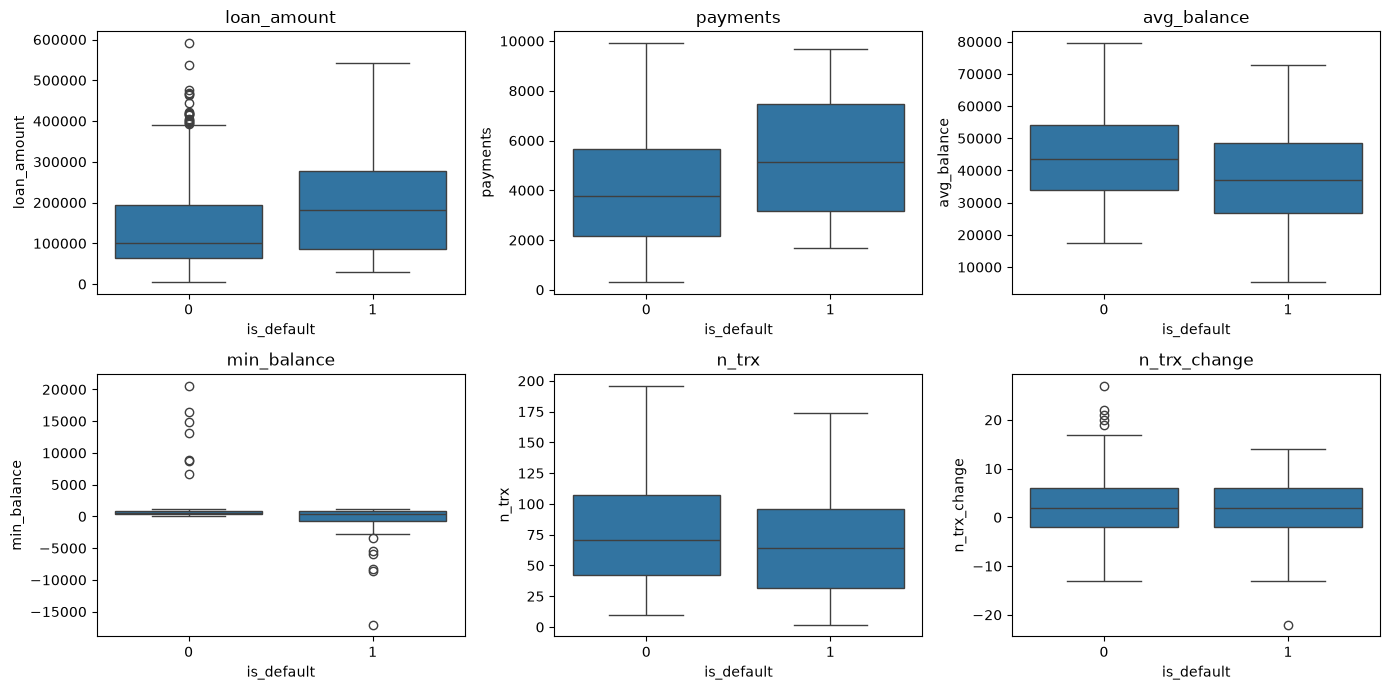

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, kolom in zip(axes.ravel(),
        ["loan_amount", "payments", "avg_balance", "min_balance", "n_trx", "n_trx_change"]):
    sns.boxplot(data=df, x="is_default", y=kolom, ax=ax)
    ax.set_title(kolom)
plt.tight_layout()
plt.show()

In [8]:
# 3 nasabah dengan rasio kosong
print(df[df["cashin_cashout_ratio"].isna()][["loan_id", "n_trx", "cash_in", "cash_out"]])

# rekening yang baru dibuka (tidak ada transaksi di bulan ke-4 sampai ke-6 sebelum pinjaman)
print("rekening baru:", (df["n_trx_prev3m"] == 0).sum())

# adakah saldo negatif?
print("saldo minimum negatif:", (df["min_balance"] < 0).sum())

     loan_id  n_trx  cash_in  cash_out
359     5314      4  20100.0       0.0
475     5063      2  10100.0       0.0
503     6594      5  22500.0       0.0
rekening baru: 0
saldo minimum negatif: 23


In [9]:
# apakah nasabah yang pernah saldo minus lebih sering bermasalah?
df["pernah_minus"] = (df["min_balance"] < 0).astype(int)
print(df.groupby("pernah_minus")["is_default"].agg(["count", "sum", "mean"]).round(3))

# status tiga nasabah tanpa pengeluaran
print(df[df["cashin_cashout_ratio"].isna()][["loan_id", "is_default"]])

              count  sum   mean
pernah_minus                   
0               501   49  0.098
1                23   23  1.000
     loan_id  is_default
359     5314           1
475     5063           1
503     6594           1


In [10]:
df["loan_date"] = pd.to_datetime(df["loan_date"])

kolom_id = ["loan_id", "account_id", "loan_date"]
y = df["is_default"]
X = df.drop(columns=kolom_id + ["is_default"])
print(X.shape)
print(list(X.columns))

(524, 14)
['loan_amount', 'duration', 'payments', 'n_trx', 'avg_balance', 'min_balance', 'cash_in', 'cash_out', 'cashin_cashout_ratio', 'n_trx_last3m', 'n_trx_prev3m', 'n_trx_change', 'avg_bal_last3m', 'pernah_minus']


In [11]:
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)
skor = {"roc_auc": "roc_auc", "pr_auc": "average_precision"}

dummy = DummyClassifier(strategy="prior")
logreg = make_pipeline(
    SimpleImputer(strategy="median", add_indicator=True),
    StandardScaler(),
    LogisticRegression(class_weight="balanced", max_iter=1000),
)

for nama, model in [("Dummy", dummy), ("Logistic Regression", logreg)]:
    h = cross_validate(model, X, y, cv=cv, scoring=skor)
    print(f"{nama}: ROC-AUC {h['test_roc_auc'].mean():.3f} ± {h['test_roc_auc'].std():.3f} | "
          f"PR-AUC {h['test_pr_auc'].mean():.3f} ± {h['test_pr_auc'].std():.3f}")

Dummy: ROC-AUC 0.500 ± 0.000 | PR-AUC 0.137 ± 0.004
Logistic Regression: ROC-AUC 0.815 ± 0.053 | PR-AUC 0.635 ± 0.092


In [12]:
tanpa_minus = [c for c in X.columns if c not in ["pernah_minus", "min_balance"]]

for nama, kolom in [("Semua fitur", list(X.columns)),
                    ("Tanpa saldo minus & min_balance", tanpa_minus)]:
    h = cross_validate(logreg, X[kolom], y, cv=cv, scoring=skor)
    print(f"{nama}: ROC-AUC {h['test_roc_auc'].mean():.3f} ± {h['test_roc_auc'].std():.3f} | "
          f"PR-AUC {h['test_pr_auc'].mean():.3f} ± {h['test_pr_auc'].std():.3f}")

Semua fitur: ROC-AUC 0.815 ± 0.053 | PR-AUC 0.635 ± 0.092
Tanpa saldo minus & min_balance: ROC-AUC 0.768 ± 0.053 | PR-AUC 0.442 ± 0.101


In [13]:
q = """
WITH l AS (
  SELECT loan_id, account_id,
         TO_DATE('19' || date::text, 'YYYYMMDD') AS loan_date
  FROM loan
)
SELECT l.loan_id, l.loan_date,
       MIN(TO_DATE('19' || t.date::text, 'YYYYMMDD')) AS first_neg,
       MIN(t.balance) AS min_bal
FROM l
JOIN trans t
  ON t.account_id = l.account_id
 AND TO_DATE('19' || t.date::text, 'YYYYMMDD') < l.loan_date
WHERE t.balance < 0
GROUP BY l.loan_id, l.loan_date
"""
neg = pd.read_sql(q, engine)
neg["hari_sebelum_loan"] = (pd.to_datetime(neg["loan_date"]) - pd.to_datetime(neg["first_neg"])).dt.days
print(neg["hari_sebelum_loan"].describe())

count     27.000000
mean     159.814815
std      119.332772
min       15.000000
25%       57.500000
50%      140.000000
75%      215.500000
max      404.000000
Name: hari_sebelum_loan, dtype: float64


In [14]:
from xgboost import XGBClassifier

rasio = (y == 0).sum() / (y == 1).sum()      # sekitar 6,3: berapa kali lipat lancar vs bermasalah

xgb = XGBClassifier(
    n_estimators=200, max_depth=2, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8, min_child_weight=3,
    scale_pos_weight=rasio, eval_metric="logloss", random_state=42,
)

for nama, model in [("Logistic Regression", logreg), ("XGBoost", xgb)]:
    h = cross_validate(model, X, y, cv=cv, scoring=skor)
    print(f"{nama}: ROC-AUC {h['test_roc_auc'].mean():.3f} ± {h['test_roc_auc'].std():.3f} | "
          f"PR-AUC {h['test_pr_auc'].mean():.3f} ± {h['test_pr_auc'].std():.3f}")

Logistic Regression: ROC-AUC 0.815 ± 0.053 | PR-AUC 0.635 ± 0.092
XGBoost: ROC-AUC 0.839 ± 0.046 | PR-AUC 0.673 ± 0.095


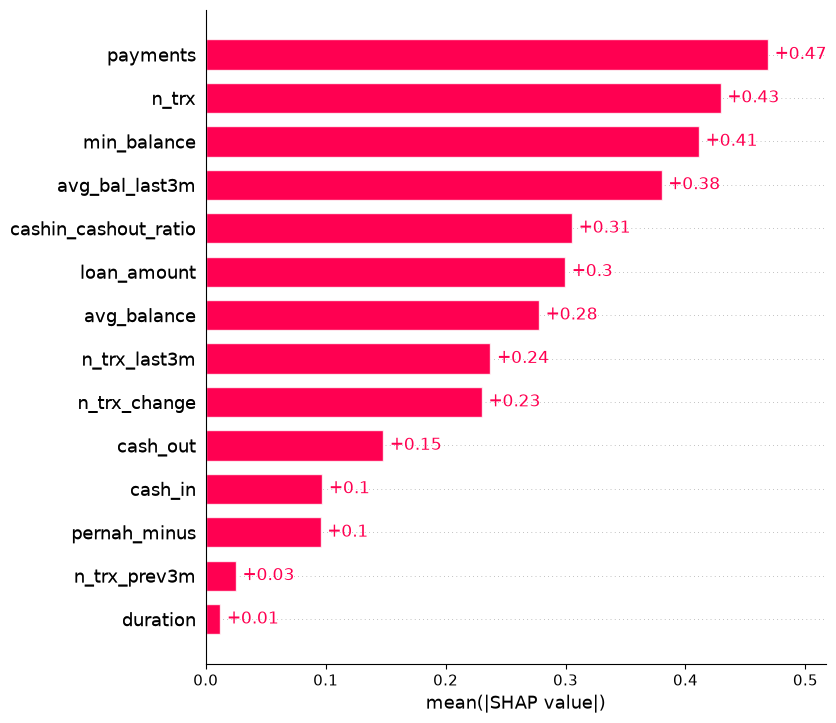

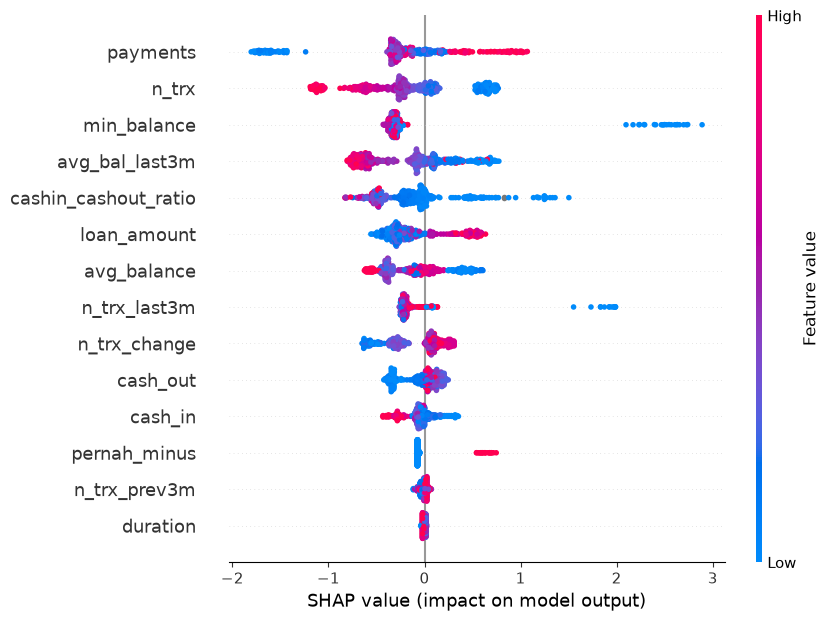

In [15]:
import shap

xgb.fit(X, y)                       
explainer = shap.TreeExplainer(xgb)
sv = explainer(X)

shap.plots.bar(sv, max_display=14)       
shap.plots.beeswarm(sv, max_display=14)  

In [16]:
h_lr = cross_validate(logreg, X, y, cv=cv, scoring=skor)
h_xg = cross_validate(xgb, X, y, cv=cv, scoring=skor)
for m in ["roc_auc", "pr_auc"]:
    d = h_xg[f"test_{m}"] - h_lr[f"test_{m}"]
    print(f"{m}: selisih rata-rata {d.mean():+.3f}, XGBoost menang di {(d > 0).sum()} dari {len(d)} lipatan")

roc_auc: selisih rata-rata +0.024, XGBoost menang di 11 dari 15 lipatan
pr_auc: selisih rata-rata +0.038, XGBoost menang di 12 dari 15 lipatan


In [17]:
import numpy as np
from sklearn.model_selection import StratifiedKFold, cross_val_predict

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
p = cross_val_predict(xgb, X, y, cv=skf, method="predict_proba")[:, 1]
urut = np.argsort(-p)

for persen in [10, 20, 30, 40]:
    n = int(len(p) * persen / 100)
    tangkap = int(y.iloc[urut[:n]].sum())
    print(f"Tolak {persen}% paling berisiko ({n} orang): tertangkap {tangkap}/{y.sum()} "
          f"(recall {tangkap/y.sum():.2f}), precision {tangkap/n:.2f}, nasabah baik ikut ditolak {n - tangkap}")

Tolak 10% paling berisiko (52 orang): tertangkap 34/72 (recall 0.47), precision 0.65, nasabah baik ikut ditolak 18
Tolak 20% paling berisiko (104 orang): tertangkap 47/72 (recall 0.65), precision 0.45, nasabah baik ikut ditolak 57
Tolak 30% paling berisiko (157 orang): tertangkap 52/72 (recall 0.72), precision 0.33, nasabah baik ikut ditolak 105
Tolak 40% paling berisiko (209 orang): tertangkap 55/72 (recall 0.76), precision 0.26, nasabah baik ikut ditolak 154


In [18]:
top = urut[:int(len(p) * 0.10)]
minus = df["pernah_minus"].to_numpy()
yv = y.to_numpy()
print("overdraft di 10% teratas:", minus[top].sum(), "dari", minus.sum())
print("bermasalah NON-overdraft yang tertangkap:", int(((yv[top] == 1) & (minus[top] == 0)).sum()))

overdraft di 10% teratas: 21 dari 23
bermasalah NON-overdraft yang tertangkap: 13


In [19]:
print(df.groupby(df["loan_date"].dt.year)["n_trx"].median())

loan_date
1993    28.0
1994    70.0
1995    87.5
1996    66.0
1997    75.0
Name: n_trx, dtype: float64
